# Real tomato data: storage-scenario experiment

**Interpretation warning:** synthetic scores only describe simulator reconstruction. Real source records keep their published target; no unrelated studies are joined.

## What the target means
Zenodo tomato table: 52 random-sample rows, 12 Rs/R0 channels plus weight/colour/storage day. The label is a storage-scenario code (`Tc`, `Trt`, `Trtd`), not inspected spoilage or remaining life. A separate continuous cohort has only nine tracked tomatoes; show it separately.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'artifacts').exists(): ROOT=ROOT.parent
ART=ROOT/'artifacts'
plt.rcParams.update({'figure.figsize':(9,4.5),'axes.spines.top':False,'axes.spines.right':False})
report=json.loads((ART/'public_tomato'/'metrics.json').read_text()); print(report['source']); print('Rows:',report['rows'],'; target counts:',report['target_counts']); print('Source warning: scenario classification only, not spoilage prediction.')

Zenodo 15469472, Sensor and Laboratory Data/Dataframe_ML_complete.csv
Rows: 52 ; target counts: {'Tc': 18, 'Trt': 16, 'Trtd': 18}
Source warning: scenario classification only, not spoilage prediction.


## Leave-one-storage-day-out validation

,Inputs,Model,Macro F1,Accuracy,Log loss
0,12 MQ,majority,0.171,0.346,1.101
1,12 MQ,random_forest,0.514,0.519,1.024
2,12 MQ,xgboost,0.498,0.519,1.005
3,12 MQ,svc,0.315,0.346,1.115
4,MQ + weight/colour,majority,0.171,0.346,1.101
5,MQ + weight/colour,random_forest,0.472,0.481,1.032
6,MQ + weight/colour,xgboost,0.546,0.558,1.037
7,MQ + weight/colour,svc,0.453,0.481,1.059


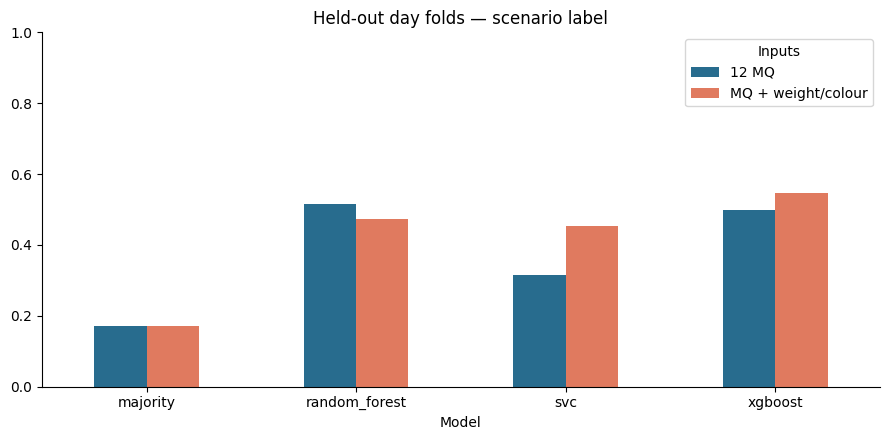

,Input,Model,Tc,Trt,Trtd
0,12 MQ,majority,1.00,0.00,0.00
1,12 MQ,random_forest,0.67,0.44,0.44
2,12 MQ,xgboost,0.78,0.50,0.28
3,12 MQ,svc,0.61,0.12,0.28
4,MQ + weight/colour,majority,1.00,0.00,0.00
5,MQ + weight/colour,random_forest,0.67,0.44,0.33
6,MQ + weight/colour,xgboost,0.72,0.38,0.56
7,MQ + weight/colour,svc,0.61,0.19,0.61


In [2]:
cv=[x for x in report['modes'] if x['validation_protocol'].startswith('leave-one-storage-day-out')]
df=pd.DataFrame([{'Inputs':'12 MQ' if x['feature_set']=='mq_12' else 'MQ + weight/colour','Model':x['model'],'Macro F1':x['macro_f1_oof'],'Accuracy':x['accuracy_oof'],'Log loss':x['log_loss_oof']} for x in cv]); display(df.round(3)); df.pivot(index='Model',columns='Inputs',values='Macro F1').plot.bar(ylim=(0,1),color=['#286c8e','#e07a5f']); plt.title('Held-out day folds — scenario label'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
rec=pd.DataFrame([{'Input':'12 MQ' if x['feature_set']=='mq_12' else 'MQ + weight/colour','Model':x['model'],**x['per_class_recall_oof']} for x in cv]); display(rec.round(2))

## Independent continuous cohort: one day-3 point from each of nine tomatoes

,Input,Model,Macro F1,Accuracy,Independent tomatoes
0,12 MQ,majority,0.167,0.333,9
1,12 MQ,random_forest,0.278,0.333,9
2,12 MQ,xgboost,0.278,0.333,9
3,12 MQ,svc,0.533,0.556,9
4,MQ + weight/colour,majority,0.167,0.333,9
5,MQ + weight/colour,random_forest,0.356,0.444,9
6,MQ + weight/colour,xgboost,0.278,0.333,9
7,MQ + weight/colour,svc,0.345,0.444,9


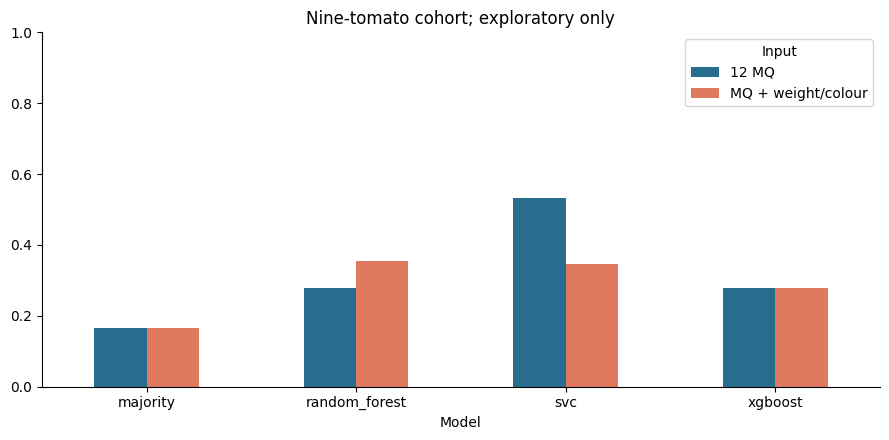

This small cohort is not a validated spoilage result.


In [3]:
ext=pd.DataFrame([{'Input':'12 MQ' if x['feature_set']=='mq_12' else 'MQ + weight/colour','Model':x['model'],'Macro F1':x['macro_f1'],'Accuracy':x['accuracy'],'Independent tomatoes':x['n_independent_tomatoes']} for x in report['independent_continuous_test']]); display(ext.round(3)); ext.pivot(index='Model',columns='Input',values='Macro F1').plot.bar(ylim=(0,1),color=['#286c8e','#e07a5f']); plt.title('Nine-tomato cohort; exploratory only'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print('This small cohort is not a validated spoilage result.')